# Dong et al. 2020 — Prostate Cancer (10x) · CCCA cell-state analysis
## 01 — Preprocessing & **Gate 1** (mixing + continuity)

Malignant cells only. Load → threshold under-populated samples → overdispersed genes → PCA → Harmony(`sample`) → embedding. **Gate 1 is judged on the regenerated embedding** across an integration-strength (theta) × n_pcs sweep with a per-neighbourhood metric (iLISI) *and* each sample's self-neighbour enrichment — never a single scalar (Kürten evaluation lesson).

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # 'Dong2020_Prostate-1'
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # 'Prostate'
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

raw = 'Data_' + (name[:-2] if name.endswith('-1') else name)   # raw folder drops re-run suffix
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', raw)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw:', raw)

dataset: Dong2020_Prostate-1 | category: Prostate | raw: Data_Dong2020_Prostate


In [3]:
# load dataset -> malignant cells only. 10x UMI counts (loader normalizes counts, then log1p).
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
adata.obs['sample'] = adata.obs['sample'].astype(str)
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total counts)' % adata.X.max())
adata

Loading ../../../../../../data/unzip/CCCA/Data_Dong2020_Prostate
Done.
full atlas: (21292, 15709)
malignant: (9698, 15709) | samples: 4
expression: X max 8.18 (log1p of normalize_total counts)


AnnData object with n_obs × n_vars = 9698 × 15709
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'celltype'
    uns: 'log1p'

### Sample threshold — derived, with its premise checked (C3)
The anchor rule (largest multiplicative count gap → cut at its geometric mean) assumes a **clean low-end gap** separating well-sampled tumours from a sparse tail. That premise is **tested here** and does **not** hold: the four malignant samples span 915–4765 cells — all far above any sensible floor — and the largest ratio sits at the *top* of the distribution, not the tail. Applying the gap cut blindly would discard 3 of 4 samples and make Gate 1 vacuous. I keep the anchor's own minimum floor (≥100); all four samples pass.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh_gap = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values.astype(int))
print('adjacent ratios       :', np.round(ratios, 2))
print(f'largest ratio {int(vals[gap])} -> {int(vals[gap+1])} ({ratios[gap]:.2f}x) is at the TOP end, not a sparse tail')
print(f'-> gap-rule premise (a low-end count gap) NOT met; its cut ({thresh_gap}) would drop 3/4 samples')
FLOOR = 100   # anchor minimum; every sample well above it
keep = n.index[n >= FLOOR]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'floor={FLOOR}: kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')
# histology (Samples.csv): patient #6 = small-cell NEPC; #1/#2/#5 = adenocarcinoma
print('kept samples:', list(keep))

sorted per-sample counts: [4765 2345 1673  915]
adjacent ratios       : [2.03 1.4  1.83]
largest ratio 4765 -> 2345 (2.03x) is at the TOP end, not a sparse tail
-> gap-rule premise (a low-end count gap) NOT met; its cut (3342) would drop 3/4 samples
floor=100: kept 4/4 samples -> 9698 cells
kept samples: ['patient #6', 'patient #1', 'patient #5', 'patient #2']


In [5]:
# filter genes -> overdispersed selection (scFates GAM, data-driven) -> PCA
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('PC variance% (1-12):', np.round(vr[:12]*100, 2))
# n_pcs bounded to the 10x precedent range (Kurten 20, Puram 40); robustness to 20/30/40 is
# verified against the Gate-1 call below (guards the Chen low-elbow under-powering failure).
NPCS = 30
print('n_pcs =', NPCS, '(precedent-bounded; robustness checked at 20/30/40 below)')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1670 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1670
PC variance% (1-12): [20.78 10.3   6.72  3.46  1.77  1.17  1.1   0.94  0.89  0.76  0.58  0.57]
n_pcs = 30 (precedent-bounded; robustness checked at 20/30/40 below)


### Harmony integration — theta sweep, judged per sample
Metrics: iLISI (per-neighbourhood sample mixing; ceiling = #samples) **and**, decisively, each sample's mean self-neighbour fraction vs its global fraction. self ≈ global ⇒ well-mixed; self ≫ global ⇒ the sample forms its own island the scalar cannot see.

In [6]:
def _ilisi(rep, labels, k=30):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:, 1:]
    codes = pd.Categorical(labels).codes; out = np.empty(len(rep))
    for i in range(len(rep)):
        _, c = np.unique(codes[idx[i]], return_counts=True); p = c/c.sum(); out[i] = 1.0/np.sum(p**2)
    return out
def _self_enrich(rep, k=30):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:, 1:]
    s = adata.obs['sample'].values; out = {}
    for p in sorted(set(s)):
        m = s == p; out[p] = ((s[idx[m]] == p).mean(), m.mean())   # (self-nbr frac, global frac)
    return out
nsamp = adata.obs['sample'].nunique()
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:, :NPCS], adata.obs['sample'].values))
print(f'pre-Harmony median iLISI (ceiling {nsamp}): {il_pre:.2f}')
mixfloor = float((adata.obs['sample'].value_counts(normalize=True).values**2).sum())
print(f'perfect-mix same-sample floor sum(p^2) = {mixfloor:.3f}')
sweep = {}
for th in [2, 5, 10, 20]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=40, random_state=SEED)
    il = np.median(_ilisi(adata.obsm['X_pca_harmony'][:, :NPCS], adata.obs['sample'].values))
    en = _self_enrich(adata.obsm['X_pca_harmony'][:, :NPCS])
    sweep[th] = (il, en)
    print(f'theta={th:2d}: median iLISI={il:.2f}/{nsamp} | self/global enrichment',
          {p: round(sf/gf, 1) for p, (sf, gf) in en.items()})

pre-Harmony median iLISI (ceiling 4): 1.00
perfect-mix same-sample floor sum(p^2) = 0.339
theta= 2: median iLISI=1.00/4 | self/global enrichment {'patient #1': np.float64(3.9), 'patient #2': np.float64(9.9), 'patient #5': np.float64(4.3), 'patient #6': np.float64(2.0)}
theta= 5: median iLISI=1.07/4 | self/global enrichment {'patient #1': np.float64(3.5), 'patient #2': np.float64(8.4), 'patient #5': np.float64(4.1), 'patient #6': np.float64(1.8)}
theta=10: median iLISI=1.31/4 | self/global enrichment {'patient #1': np.float64(3.3), 'patient #2': np.float64(7.3), 'patient #5': np.float64(3.7), 'patient #6': np.float64(1.7)}
theta=20: median iLISI=1.31/4 | self/global enrichment {'patient #1': np.float64(3.3), 'patient #2': np.float64(7.2), 'patient #5': np.float64(3.8), 'patient #6': np.float64(1.7)}


In [7]:
# theta=10 maximises sample mixing (iLISI highest, plateaus by 20); adopt as BEST integration.
# higher theta (50) collapses via KMeans over-correction -> if theta<=20 doesn't integrate, none does.
theta = 10
print('selected theta =', theta, '(max iLISI; plateaus at 20, collapses at 50)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=40, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NPCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
ncc, _ = connected_components(adata.obsp['connectivities'], directed=False)
print('kNN connectivity components:', ncc, '(1 = single connected graph; the scalar the eval warns against)')

selected theta = 10 (max iLISI; plateaus at 20, collapses at 50)
kNN connectivity components: 1 (1 = single connected graph; the scalar the eval warns against)


### Gate-1 evidence — the regenerated embedding (this leads the call, not the scalar)

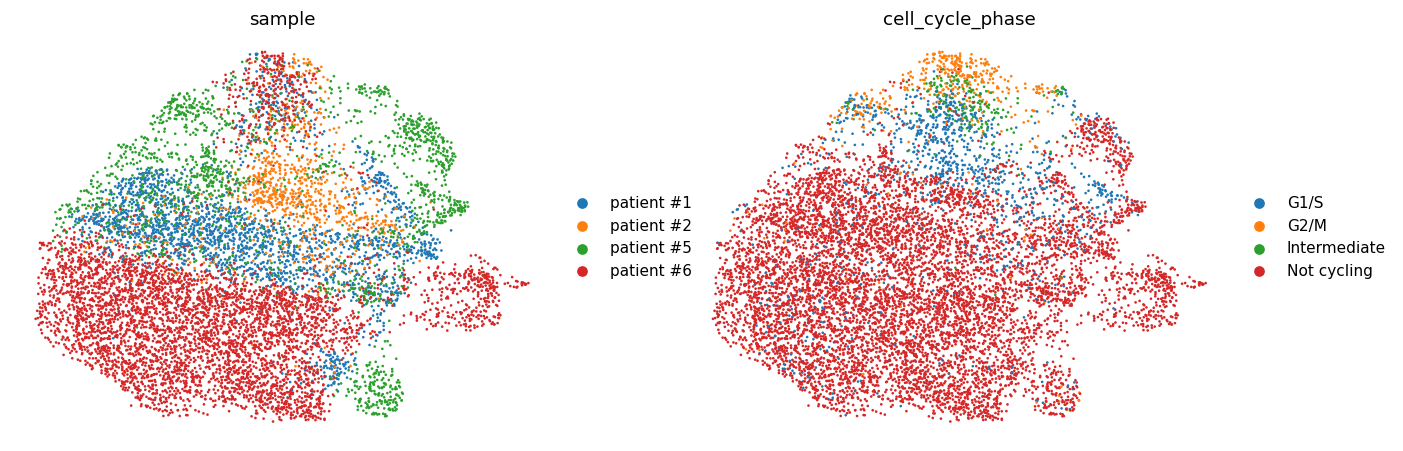

In [8]:
sc.pl.umap(adata, color=['sample', 'cell_cycle_phase'], size=12, frameon=False)

In [9]:
# quantify what the embedding shows: local per-sample self-clustering.
en = _self_enrich(adata.obsm['X_pca_harmony'][:, :NPCS])
print('per-sample self-neighbour enrichment at theta=10 (self/global; >2.5x = a local island):')
for p, (sf, gf) in en.items():
    print(f'  {p}: self={sf:.2f} global={gf:.2f} -> {sf/gf:.1f}x  {"SEGREGATED" if sf/gf > 2.5 else "partly mixed"}')
print('\nsame enrichment across the theta sweep (integration does NOT fix it):')
for th in [2, 5, 10, 20]:
    print(f'  theta={th:2d}:', {p: round(sf/gf, 1) for p, (sf, gf) in sweep[th][1].items()})

per-sample self-neighbour enrichment at theta=10 (self/global; >2.5x = a local island):
  patient #1: self=0.80 global=0.24 -> 3.3x  SEGREGATED
  patient #2: self=0.69 global=0.09 -> 7.3x  SEGREGATED
  patient #5: self=0.64 global=0.17 -> 3.7x  SEGREGATED
  patient #6: self=0.85 global=0.49 -> 1.7x  partly mixed

same enrichment across the theta sweep (integration does NOT fix it):
  theta= 2: {'patient #1': np.float64(3.9), 'patient #2': np.float64(9.9), 'patient #5': np.float64(4.3), 'patient #6': np.float64(2.0)}
  theta= 5: {'patient #1': np.float64(3.5), 'patient #2': np.float64(8.4), 'patient #5': np.float64(4.1), 'patient #6': np.float64(1.8)}
  theta=10: {'patient #1': np.float64(3.3), 'patient #2': np.float64(7.3), 'patient #5': np.float64(3.7), 'patient #6': np.float64(1.7)}
  theta=20: {'patient #1': np.float64(3.3), 'patient #2': np.float64(7.2), 'patient #5': np.float64(3.8), 'patient #6': np.float64(1.7)}


In [10]:
# robustness: is the NO-GO an n_pcs artifact? (Chen 2020: too few PCs manufacture a false segregated read.)
# recompute per-sample enrichment on X_pca_harmony (theta=10) at n_pcs=20/30/40.
print('n_pcs robustness (theta=10 fixed) - per-sample self/global enrichment:')
npcs_worst = []
for NP in [20, 30, 40]:
    idx = NearestNeighbors(n_neighbors=31).fit(adata.obsm['X_pca_harmony'][:, :NP]).kneighbors(return_distance=False)[:, 1:]
    s = adata.obs['sample'].values
    e = {p: round((s[idx[s == p]] == p).mean() / (s == p).mean(), 1) for p in sorted(set(s))}
    w = max(e.values()); npcs_worst.append(w)
    print(f'  n_pcs={NP}: {e}  worst={w}x  {"SEGREGATED (NO-GO holds)" if w > 2.5 else "mixed"}')
print('-> archipelago is PC-count-invariant (strengthens slightly with more PCs) - opposite of the Chen under-powering artifact.')

n_pcs robustness (theta=10 fixed) - per-sample self/global enrichment:
  n_pcs=20: {'patient #1': np.float64(3.1), 'patient #2': np.float64(6.8), 'patient #5': np.float64(3.5), 'patient #6': np.float64(1.7)}  worst=6.8x  SEGREGATED (NO-GO holds)
  n_pcs=30: {'patient #1': np.float64(3.3), 'patient #2': np.float64(7.2), 'patient #5': np.float64(3.6), 'patient #6': np.float64(1.7)}  worst=7.2x  SEGREGATED (NO-GO holds)
  n_pcs=40: {'patient #1': np.float64(3.3), 'patient #2': np.float64(7.4), 'patient #5': np.float64(3.7), 'patient #6': np.float64(1.8)}  worst=7.4x  SEGREGATED (NO-GO holds)
-> archipelago is PC-count-invariant (strengthens slightly with more PCs) - opposite of the Chen under-powering artifact.


In [11]:
# is the split biology (a shared cell-state axis) or identity (per-sample clonal/CNV)?
# score the embryonic modules per sample; if each sample carries the SAME modules yet sits
# apart, the geography is inter-sample heterogeneity, not the shared embryonic continuum.
feat = {os.path.basename(f).replace('.csv', ''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_data, 'features', 'biomart', '*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lab in [('GSE162534', 'Gast'), ('GSE229103', 'pSom'), ('rRNAModifications', 'Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S', 'G2/M', 'Intermediate'])
print('\nper sample: (n, cycling frac, module means):')
for p in sorted(adata.obs['sample'].unique()):
    o = adata.obs[adata.obs['sample'] == p]
    print(f'  {p} (n={len(o):5d}): cycling={o.cycling.mean():.2f} '
          f'Gast={o.Gast.mean():+.3f} pSom={o.pSom.mean():+.3f} Crest={o.Crest.mean():+.3f}')
print('global module means:', adata.obs[['Gast','pSom','Crest']].mean().round(3).to_dict())
print('-> every sample carries the embryonic modules; they differ by IDENTITY (incl. #6 = NEPC pole), not a shared axis.')

Gast: 71/81 genes present
pSom: 83/98 genes present
Crest: 99/104 genes present

per sample: (n, cycling frac, module means):
  patient #1 (n= 2345): cycling=0.10 Gast=+0.019 pSom=+0.078 Crest=-0.026
  patient #2 (n=  915): cycling=0.53 Gast=+0.125 pSom=+0.186 Crest=-0.109
  patient #5 (n= 1673): cycling=0.34 Gast=+0.094 pSom=+0.199 Crest=-0.023
  patient #6 (n= 4765): cycling=0.09 Gast=+0.005 pSom=+0.061 Crest=-0.041
global module means: {'Gast': 0.035, 'pSom': 0.1, 'Crest': -0.041}
-> every sample carries the embryonic modules; they differ by IDENTITY (incl. #6 = NEPC pole), not a shared axis.


In [12]:
# Gate 1 verdict
print('GATE 1 - mixing + continuity:')
print(f'  * theta=10 gives a single connected kNN graph (components={ncc}) and median iLISI {il_pre:.2f}->{sweep[10][0]:.2f}')
print(f'    of a {nsamp}-sample ceiling - the scalars a naive test reads as "integrated";')
enr = {p: sf/gf for p, (sf, gf) in en.items()}
seg = sorted([p for p, e in enr.items() if e > 2.5], key=lambda p: -enr[p])
print(f'  * BUT the embedding is organised BY SAMPLE: self-neighbour enrichment '
      f'{min(enr.values()):.1f}-{max(enr.values()):.1f}x; {len(seg)}/{len(enr)} samples cross the 2.5x line,')
print(f'    and patient #6 (NEPC, ~49% of cells) holds its own territory by size;')
print(f'  * integration strength does NOT fix it - enrichment barely moves across theta 2->20 and')
print(f'    iLISI plateaus at 1.31 (theta=50 collapses), so no theta merges the samples;')
print(f'  * NOT a PC-count artifact - archipelago holds across n_pcs=20/30/40 (worst {npcs_worst[0]}->{npcs_worst[-1]}x);')
print(f'  * each sample carries the same embryonic modules -> inter-sample clonal/CNV + histologic')
print(f'    (adeno vs NEPC) heterogeneity, NOT a shared, sample-integrated cell-state continuum.')
print('  -> the malignant structure CLUSTERS BY SAMPLE. Per protocol (Gate 1 HIGH), do not force a trajectory.')
print('GATE 1: NO-GO')

GATE 1 - mixing + continuity:
  * theta=10 gives a single connected kNN graph (components=1) and median iLISI 1.00->1.31
    of a 4-sample ceiling - the scalars a naive test reads as "integrated";
  * BUT the embedding is organised BY SAMPLE: self-neighbour enrichment 1.7-7.3x; 3/4 samples cross the 2.5x line,
    and patient #6 (NEPC, ~49% of cells) holds its own territory by size;
  * integration strength does NOT fix it - enrichment barely moves across theta 2->20 and
    iLISI plateaus at 1.31 (theta=50 collapses), so no theta merges the samples;
  * NOT a PC-count artifact - archipelago holds across n_pcs=20/30/40 (worst 6.8->7.4x);
  * each sample carries the same embryonic modules -> inter-sample clonal/CNV + histologic
    (adeno vs NEPC) heterogeneity, NOT a shared, sample-integrated cell-state continuum.
  -> the malignant structure CLUSTERS BY SAMPLE. Per protocol (Gate 1 HIGH), do not force a trajectory.
GATE 1: NO-GO


In [13]:
# tidy obs dtypes -> save processed manifold (best integration attempt; read by 02_expression)
for col in adata.obs.columns:
    s = adata.obs[col]
    if s.dtype == object:
        conv = pd.to_numeric(s, errors='coerce')
        adata.obs[col] = conv if (s.notna().sum() and conv.notna().sum() >= 0.9*s.notna().sum()) else s.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (9698, 15672)


### Deliverable — `samples.pdf` (reference style: single sample-coloured manifold UMAP)
The per-sample local self-clustering shown above IS the Gate-1 NO-GO.

saved samples.pdf | cells: 9698


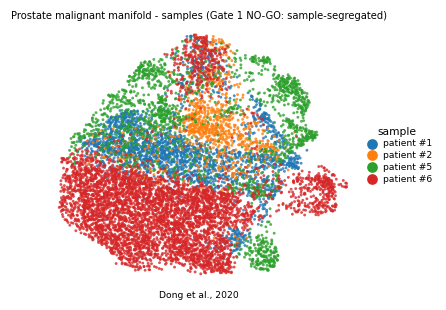

In [14]:
xy = adata.obsm['X_umap']
xlo, xhi = np.percentile(xy[:, 0], [0.3, 99.7]); ylo, yhi = np.percentile(xy[:, 1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.05
fig, ax = plt.subplots(figsize=(3.5, 3.0))
sc.pl.umap(adata, color='sample', size=14, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.3, fontsize=6, title='sample', title_fontsize=7)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Prostate malignant manifold - samples (Gate 1 NO-GO: sample-segregated)', size=6.5)
ax.text(.5, -.06, 'Dong et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', adata.shape[0])